\begin{center}
{\LARGE \textbf{EN3160 Image Processing and Machine Vision}}\\[0.5em]
{\Large Assignment 2 -- Fitting and Alignment}\\[1.5em]

\textbf{Name:} S.A.D. Priyadarshana\\[0.3em]
\textbf{Index:} 230502X\\[0.3em]
\textbf{GitHub:} \href{https://github.com/denethp/CV-Assignment-02}{denethp/CV-Assignment-02}
\end{center}

\vspace{1em}

$\underline{\textbf{Question 1}}$

In [92]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

%matplotlib inline

In [93]:
def log_kernel(sigma):
    # Scale-normalized LoG, window of +-3 sigma;
    # mean removed so the truncated kernel gives zero response on flat regions.
    hw = int(np.ceil(3 * sigma))
    X, Y = np.meshgrid(np.arange(-hw, hw + 1), np.arange(-hw, hw + 1))
    log = 1 / (2 * np.pi * sigma ** 2) * (X ** 2 / sigma ** 2 + Y ** 2 / sigma ** 2 - 2) \
          * np.exp(-(X ** 2 + Y ** 2) / (2 * sigma ** 2))
    return log - log.mean()

In [94]:
im = cv.imread('images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

sigmas = np.arange(1, 16.5, 0.5)
scale_space = np.stack([cv.filter2D(gray, -1, log_kernel(s)) for s in sigmas], axis=2)

# Scale-space extrema: maximum in the 3x3x3 (x, y, sigma) neighbourhood above a threshold.
# Dark sunflower centres on bright petals give positive LoG peaks.
threshold = 0.2
peaks = (scale_space == maximum_filter(scale_space, size=3)) & (scale_space > threshold)
peaks[:, :, [0, -1]] = False  # end scales have only one neighbouring scale

ys, xs, ks = np.nonzero(peaks)
radii = np.sqrt(2) * sigmas[ks]  # r = sqrt(2) * sigma
print(f'sigma range: {sigmas[0]} to {sigmas[-1]} (step 0.5), blobs detected: {len(ys)}')

sigma range: 1.0 to 16.0 (step 0.5), blobs detected: 104


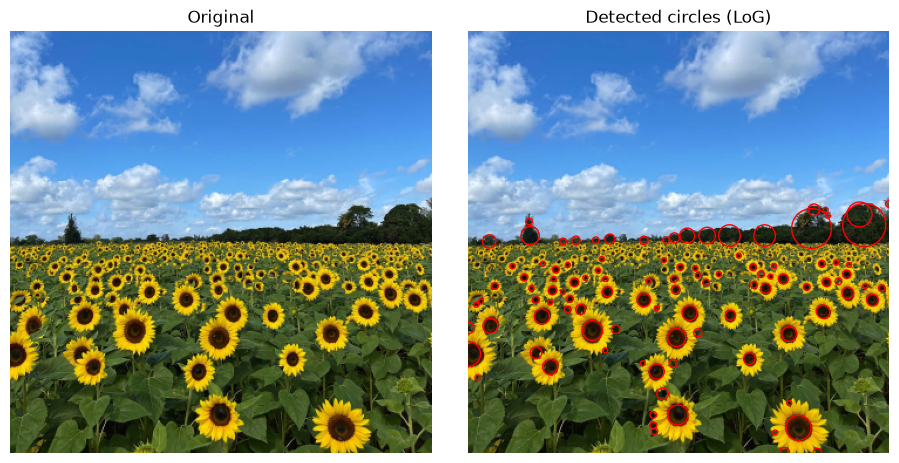

In [95]:
fig, axes = plt.subplots(1, 2, figsize=(9.3, 4.6))
axes[0].imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
axes[0].set_title('Original')
axes[0].axis('off')

axes[1].imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
for x, y, r in zip(xs, ys, radii):
    axes[1].add_patch(plt.Circle((x, y), r, color='r', fill=False, linewidth=1))
axes[1].set_title('Detected circles (LoG)')
axes[1].axis('off')
plt.tight_layout()
plt.show()

In [96]:
order = np.argsort(-radii)[:5]
print('  x    y   sigma  radius')
for o in order:
    print(f'{xs[o]:3d}  {ys[o]:3d}  {sigmas[ks[o]]:5.1f}  {radii[o]:6.2f}')

  x    y   sigma  radius
338  165   13.0   18.38
293  168   12.0   16.97
334  156    7.5   10.61
  0  275    7.5   10.61
282  338    7.5   10.61


$\textbf{Discussion:}$ the image is converted to grayscale and filtered with scale-normalized LoG kernels for $\sigma \in [1, 16]$ (step 0.5). A blob is a point that is a maximum among its 26 neighbours in $(x, y, \sigma)$ and whose response exceeds 0.2; the circle radius is $r = \sqrt{2}\sigma$. The largest circles are at (338, 165) with $\sigma = 13$ ($r \approx 18.4$) and (293, 168) with $\sigma = 12$ ($r \approx 17.0$), but these lie on the dark tree line against the bright sky rather than on flowers. The largest circles on sunflowers have $\sigma = 7.5$ ($r \approx 10.6$), e.g. the large flower at (282, 338). Almost every sunflower centre is detected, and smaller $\sigma$ values pick up the more distant flowers, showing the scale selection at work. Because LoG responds to any dark blob on a lighter background, some false detections appear along the tree line and in leaf shadows; a higher threshold or restricting detection to the field region would remove these.

$\underline{\textbf{Question 2}}$

In [97]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Noisy point set conforming to a line and a circle
np.random.seed(0)
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3  # Center
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line))  # All points

$\textbf{(a) Estimating the line with RANSAC}$

Line model: $ax + by = d$ with $\|[a, b]^\top\| = 1$. Error is the normal distance $|ax_i + by_i - d|$.

In [98]:
def line_from_points(p1, p2):
    # Unit normal [a, b] and distance d of the line through two points
    dx, dy = p2 - p1
    norm = np.hypot(dx, dy)
    a, b = dy / norm, -dx / norm
    return np.array([a, b, a * p1[0] + b * p1[1]])

def line_tls(params, pts):
    # Total least squares: sum of squared normal distances
    a, b, d = params
    return np.sum((a * pts[:, 0] + b * pts[:, 1] - d) ** 2)

# Constraint ||[a, b]|| = 1
cons = ({'type': 'eq', 'fun': lambda p: p[0] ** 2 + p[1] ** 2 - 1})

def line_consensus(params, pts, t):
    a, b, d = params
    return np.abs(a * pts[:, 0] + b * pts[:, 1] - d) < t

def ransac_line(pts, t, min_inliers, max_iterations):
    best_count = 0
    for _ in range(max_iterations):
        idx = np.random.choice(len(pts), 2, replace=False)  # minimal sample of 2 points
        model = line_from_points(pts[idx[0]], pts[idx[1]])
        inliers = line_consensus(model, pts, t)
        if inliers.sum() >= min_inliers and inliers.sum() > best_count:
            best_count = inliers.sum()
            best_sample, best_sample_model, best_inliers = pts[idx], model, inliers
    if best_count == 0:
        return None  # no sample reached the required consensus
    # Re-estimate the line from all inliers of the best sample
    res = minimize(line_tls, best_sample_model, args=(pts[best_inliers],), constraints=cons)
    return res.x, best_sample_model, best_sample, best_inliers

a = 0.726, b = 0.688, d = 1.591, ||[a, b]|| = 1.000
slope = -1.054, intercept = 2.312, inliers = 47


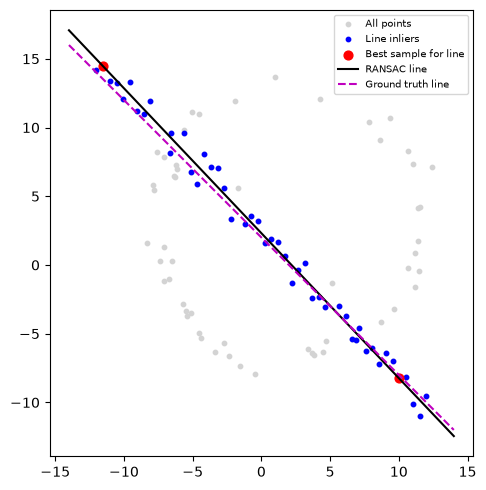

In [99]:
t_line = 1.0  # normal-distance threshold
d_line = 40   # minimum consensus size
line_model, line_sample_model, line_sample, line_inliers = ransac_line(X, t_line, d_line, 100)

a_l, b_l, d_l = line_model  # (m, b are kept for the ground truth)
print(f'a = {a_l:.3f}, b = {b_l:.3f}, d = {d_l:.3f}, ||[a, b]|| = {np.hypot(a_l, b_l):.3f}')
print(f'slope = {-a_l / b_l:.3f}, intercept = {d_l / b_l:.3f}, inliers = {line_inliers.sum()}')

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X[:, 0], X[:, 1], s=10, color='lightgray', label='All points')
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], s=10, color='b', label='Line inliers')
ax.scatter(line_sample[:, 0], line_sample[:, 1], s=40, color='r', label='Best sample for line')
x_ = np.array([-14, 14])
ax.plot(x_, (d_l - a_l * x_) / b_l, color='k', label='RANSAC line')
ax.plot(x_, m * x_ + b, 'm--', label='Ground truth line')
ax.set_aspect('equal')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

$\textbf{Parameter choice:}$ the line noise has $\sigma = 1$ in $y$, so the normal-distance noise is about $1/\sqrt{2} \approx 0.71$; a threshold $t = 1.0$ keeps most true line points. The line has 50 points, so a consensus of at least 40 is required. Each sample uses the minimum of 2 points, and the final line is re-estimated from all inliers by minimizing the total least squares error with the constraint $\|[a, b]^\top\| = 1$.

$\textbf{(b) Estimating the circle from the remnant with RANSAC}$

Circle model: centre $(x_c, y_c)$ and radius $r$. Error is the radial distance $\left|\sqrt{(x_i - x_c)^2 + (y_i - y_c)^2} - r\right|$.

In [100]:
def circle_from_points(p1, p2, p3):
    # Circumcircle of three points (None if they are nearly collinear)
    A = np.array([p2 - p1, p3 - p1]) * 2
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    if abs(np.linalg.det(A)) < 1e-6:
        return None
    centre = np.linalg.solve(A, rhs)
    return np.array([centre[0], centre[1], np.linalg.norm(p1 - centre)])

def radial_error(params, pts):
    xc, yc, rc = params
    return np.abs(np.hypot(pts[:, 0] - xc, pts[:, 1] - yc) - rc)

def circle_lsq(params, pts):
    return np.sum(radial_error(params, pts) ** 2)

def ransac_circle(pts, t, min_inliers, max_iterations):
    best_count = 0
    for _ in range(max_iterations):
        idx = np.random.choice(len(pts), 3, replace=False)  # minimal sample of 3 points
        model = circle_from_points(*pts[idx])
        if model is None:
            continue
        inliers = radial_error(model, pts) < t
        if inliers.sum() >= min_inliers and inliers.sum() > best_count:
            best_count = inliers.sum()
            best_sample, best_sample_model, best_inliers = pts[idx], model, inliers
    if best_count == 0:
        return None  # no sample reached the required consensus
    # Re-estimate the circle from all inliers of the best sample
    res = minimize(circle_lsq, best_sample_model, args=(pts[best_inliers],))
    return res.x, best_sample_model, best_sample, best_inliers

remnant points = 53
centre = (1.895, 2.962), radius = 9.854, inliers = 50


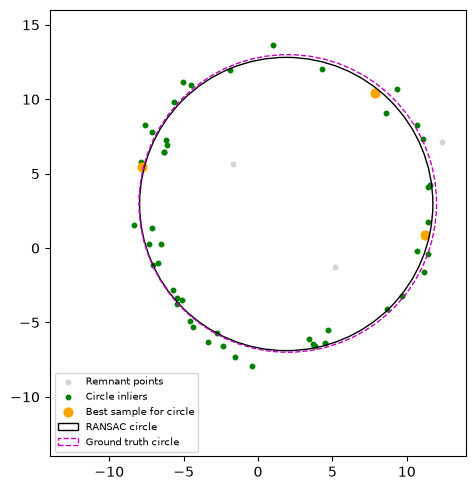

In [101]:
X_rem = X[~line_inliers]  # subtract the consensus of the best line

t_circ = 1.25  # radial-error threshold (2 x noise std r/16)
d_circ = 35    # minimum consensus size
circ_model, circ_sample_model, circ_sample, circ_inliers = ransac_circle(X_rem, t_circ, d_circ, 100)

xc, yc, rc = circ_model
print(f'remnant points = {len(X_rem)}')
print(f'centre = ({xc:.3f}, {yc:.3f}), radius = {rc:.3f}, inliers = {circ_inliers.sum()}')

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_rem[:, 0], X_rem[:, 1], s=10, color='lightgray', label='Remnant points')
ax.scatter(X_rem[circ_inliers, 0], X_rem[circ_inliers, 1], s=10, color='g', label='Circle inliers')
ax.scatter(circ_sample[:, 0], circ_sample[:, 1], s=40, color='orange', label='Best sample for circle')
ax.add_patch(plt.Circle((xc, yc), rc, color='k', fill=False, label='RANSAC circle'))
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='m', fill=False, linestyle='--', label='Ground truth circle'))
ax.set_xlim(-14, 14)
ax.set_ylim(-14, 16)
ax.set_aspect('equal')
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

$\textbf{Parameter choice:}$ the circle points have radial noise with $\sigma = r/16 = 0.625$, so a threshold $t = 1.25$ ($2\sigma$) keeps almost all true circle points. Of the 50 circle points a few are removed as line inliers where the line crosses the circle, so a consensus of at least 35 is required. Each sample uses the minimum of 3 points (circumcircle), and the final circle is re-estimated from all inliers by minimizing the sum of squared radial errors.

$\textbf{(c) Line and circle estimated with RANSAC}$

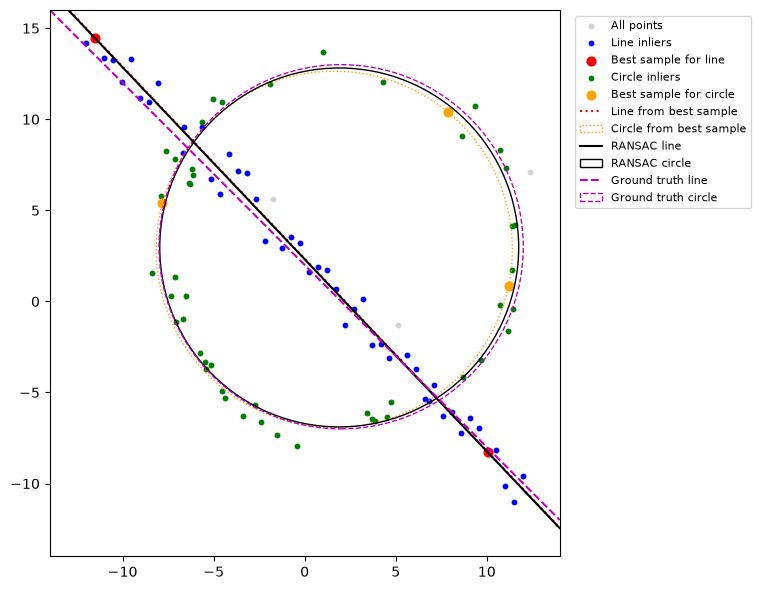

In [102]:
x_ = np.array([-14, 14])

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.scatter(X[:, 0], X[:, 1], s=10, color='lightgray', label='All points')
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], s=10, color='b', label='Line inliers')
ax.scatter(line_sample[:, 0], line_sample[:, 1], s=40, color='r', label='Best sample for line')
ax.scatter(X_rem[circ_inliers, 0], X_rem[circ_inliers, 1], s=10, color='g', label='Circle inliers')
ax.scatter(circ_sample[:, 0], circ_sample[:, 1], s=40, color='orange', label='Best sample for circle')

# Models estimated only from the best samples
a_s, b_s, d_s = line_sample_model
ax.plot(x_, (d_s - a_s * x_) / b_s, color='r', linestyle=':', label='Line from best sample')
ax.add_patch(plt.Circle(circ_sample_model[:2], circ_sample_model[2], color='orange', fill=False,
                        linestyle=':', label='Circle from best sample'))

# Best-fit models (re-estimated from all inliers)
ax.plot(x_, (d_l - a_l * x_) / b_l, color='k', label='RANSAC line')
ax.add_patch(plt.Circle((xc, yc), rc, color='k', fill=False, label='RANSAC circle'))

# Ground truth
ax.plot(x_, m * x_ + b, color='m', linestyle='--', label='Ground truth line')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='m', fill=False, linestyle='--', label='Ground truth circle'))

ax.set_xlim(-14, 14)
ax.set_ylim(-14, 16)
ax.set_aspect('equal')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

$\textbf{(d) Fitting the circle first}$

circle: centre = (1.90, 3.02), r = 9.88, inliers = 57
line points taken by the circle = 9 (line-first: circle points taken by the line = 2)
line points left = 41
line with consensus 40: failed
seed 43 circle: r = 1300.6, inliers = 52 (line points: 49)


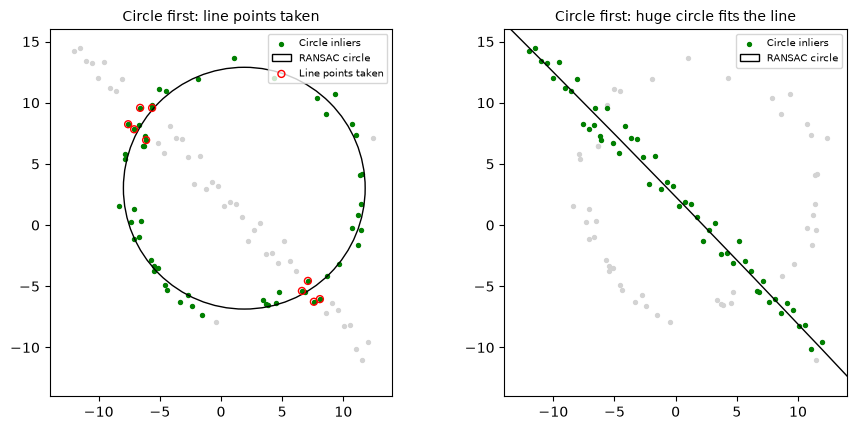

In [103]:
# Case 1: circle first on all points, then the line on the remnant
np.random.seed(1)
c_model, _, _, c_inl = ransac_circle(X, t_circ, d_circ, 100)
print(f'circle: centre = ({c_model[0]:.2f}, {c_model[1]:.2f}), r = {c_model[2]:.2f}, inliers = {c_inl.sum()}')
print(f'line points taken by the circle = {c_inl[half_n:].sum()} '
      f'(line-first: circle points taken by the line = {line_inliers[:half_n].sum()})')
X_rem2 = X[~c_inl]
print(f'line points left = {(~c_inl[half_n:]).sum()}')
print('line with consensus 40:', 'failed' if ransac_line(X_rem2, t_line, d_line, 100) is None else 'found')

# Case 2: a seed where a huge circle fits the line points
np.random.seed(43)
big_model, _, _, big_inl = ransac_circle(X, t_circ, d_circ, 100)
print(f'seed 43 circle: r = {big_model[2]:.1f}, inliers = {big_inl.sum()} (line points: {big_inl[half_n:].sum()})')

fig, axes = plt.subplots(1, 2, figsize=(9.3, 4.4))
for ax, inl, model, title in [(axes[0], c_inl, c_model, 'Circle first: line points taken'),
                              (axes[1], big_inl, big_model, 'Circle first: huge circle fits the line')]:
    ax.scatter(X[:, 0], X[:, 1], s=8, color='lightgray')
    ax.scatter(X[inl, 0], X[inl, 1], s=8, color='g', label='Circle inliers')
    ax.add_patch(plt.Circle(model[:2], model[2], color='k', fill=False, label='RANSAC circle'))
    ax.set_xlim(-14, 14)
    ax.set_ylim(-14, 16)
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=7, loc='upper right')
taken = c_inl.copy()
taken[:half_n] = False
axes[0].scatter(X[taken, 0], X[taken, 1], s=25, facecolors='none', edgecolors='r', label='Line points taken')
axes[0].legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

$\textbf{Discussion:}$ fitting the line first works well because the line is a thin structure: its 1.0 band only crosses the circle at two places and takes just 2 circle points, leaving a clean remnant for the circle. If the circle is fitted first, its wider band (radial threshold 1.25 on both sides) overlaps the line where it crosses the circle, so the circle takes 9 line points. Only 41 line points remain, the line RANSAC with consensus 40 then fails, and the consensus has to be lowered, which makes it easier to accept wrong lines. The stolen points also bias the circle fit slightly. In addition, a circle with a very large radius is locally almost straight, so RANSAC can return a "circle" that is really the line (seed 43: $r \approx 1300$ with 52 inliers, almost all line points), after which no line remains to be found. Therefore the simpler, thinner model (the line) should be fitted first and its consensus removed before fitting the circle.

$\underline{\textbf{Question 3}}$

In [104]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def select_points(im, n=4):
    # Click n points on the image (order: top-left, top-right, bottom-right, bottom-left)
    pts = []
    def on_click(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN and len(pts) < n:
            pts.append([x, y])
            cv.circle(disp, (x, y), 5, (0, 0, 255), -1)
            cv.imshow('Select points', disp)
    disp = im.copy()
    cv.imshow('Select points', disp)
    cv.setMouseCallback('Select points', on_click)
    while len(pts) < n:
        cv.waitKey(20)
    cv.destroyAllWindows()
    return np.array(pts, dtype=np.float32)

def overlay(im_dst, im_src, pts_dst, alpha=0.8):
    # Homography mapping the corners of im_src to the clicked points, then warp and blend
    h, w = im_src.shape[:2]
    pts_src = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], dtype=np.float32)
    H, _ = cv.findHomography(pts_src, pts_dst)
    size = (im_dst.shape[1], im_dst.shape[0])
    warped = cv.warpPerspective(im_src, H, size)
    mask = cv.warpPerspective(np.full((h, w), 255, np.uint8), H, size) > 0
    blended = cv.addWeighted(im_dst, 1 - alpha, warped, alpha, 0)
    out = im_dst.copy()
    out[mask] = blended[mask]  # blend only inside the warped flag region
    return out, H

H =
 [[2.299e-01 0.000e+00 1.500e+02]
 [6.760e-02 2.138e-01 2.250e+02]
 [1.000e-04 0.000e+00 1.000e+00]]


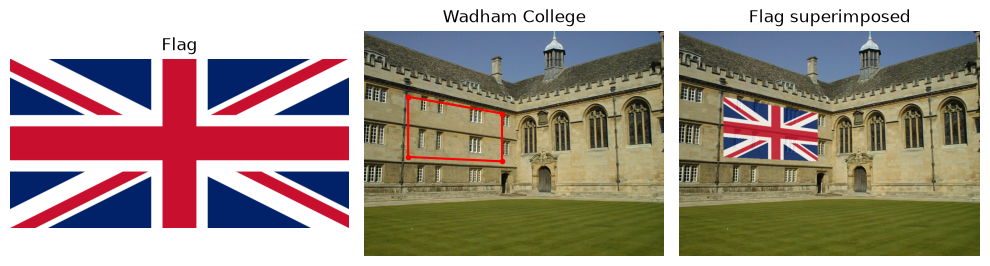

In [105]:
im = cv.imread('images/wadham.jpg')
flag = cv.imread('images/flag.png')

# pts = select_points(im)  # uncomment to click the points again
pts = np.array([[150, 225], [470, 282], [470, 445], [150, 430]], dtype=np.float32)  # clicked points
result, H = overlay(im, flag, pts)
print('H =\n', np.round(H, 4))

fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), gridspec_kw={'width_ratios': [1.5, 1.33, 1.33]})
for ax, (img, title) in zip(axes, [(flag, 'Flag'), (im, 'Wadham College'), (result, 'Flag superimposed')]):
    ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
axes[1].plot(*np.vstack([pts, pts[:1]]).T, 'r.-')
plt.tight_layout()
plt.show()

$\textbf{Own image pair 1: a photo on a laptop screen}$

H =
 [[ 2.366e-01  2.090e-02  3.130e+02]
 [ 2.410e-02  3.134e-01  5.500e+01]
 [-2.000e-04  1.000e-04  1.000e+00]]


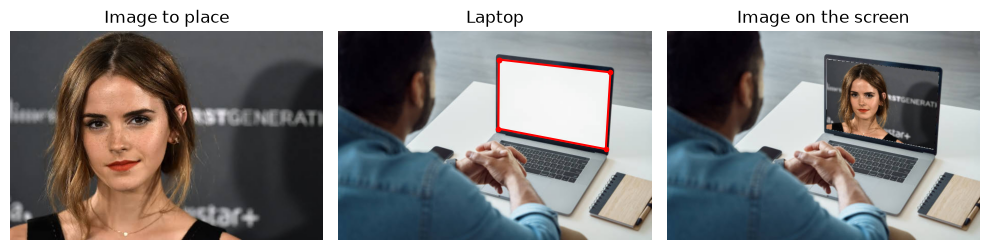

In [106]:
laptop = cv.imread('images/laptop.jpg')
emma = cv.imread('images/emma.jpg')

# pts = select_points(laptop)  # uncomment to click the points again
pts_laptop = np.array([[313, 55], [531, 80], [522, 230], [312, 190]], dtype=np.float32)  # screen corners
result_laptop, H_laptop = overlay(laptop, emma, pts_laptop, alpha=1.0)  # opaque, like a real display
print('H =\n', np.round(H_laptop, 4))

fig, axes = plt.subplots(1, 3, figsize=(10, 2.6))
for ax, (img, title) in zip(axes, [(emma, 'Image to place'), (laptop, 'Laptop'), (result_laptop, 'Image on the screen')]):
    ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
axes[1].plot(*np.vstack([pts_laptop, pts_laptop[:1]]).T, 'r.-')
plt.tight_layout()
plt.show()

$\textbf{Rationale:}$ a laptop screen is a planar rectangle with four clearly visible corners, and here it is viewed at an angle, so the homography has to correct a real perspective distortion (the right edge of the screen is shorter than the left). This is the same idea used for product mockups, where a design or photo is placed onto a device in a stock photograph. A blank white screen makes the result easy to judge, and $\alpha = 1$ is used so the photo appears as if it is being displayed by the screen.

$\textbf{Own image pair 2: an advert on a roadside billboard}$

H =
 [[ 6.159e-01 -6.400e-03  4.610e+02]
 [ 1.120e-02  4.510e-01  1.340e+02]
 [ 0.000e+00 -0.000e+00  1.000e+00]]


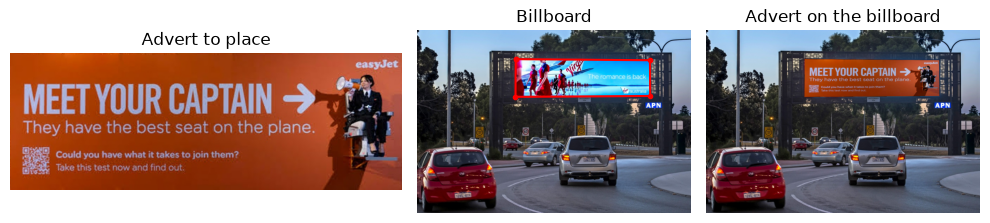

In [107]:
billboard = cv.imread('images/billboard.jpg')
ad = cv.imread('images/easyjet_ad.jpg')

# pts = select_points(billboard)  # uncomment to click the points again
pts_board = np.array([[461, 134], [1088, 139], [1089, 306], [460, 310]], dtype=np.float32)  # screen corners
result_board, H_board = overlay(billboard, ad, pts_board, alpha=1.0)
print('H =\n', np.round(H_board, 4))

fig, axes = plt.subplots(1, 3, figsize=(10, 2.4), gridspec_kw={'width_ratios': [1.43, 1, 1]})
for ax, (img, title) in zip(axes, [(ad, 'Advert to place'), (billboard, 'Billboard'), (result_board, 'Advert on the billboard')]):
    ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis('off')
axes[1].plot(*np.vstack([pts_board, pts_board[:1]]).T, 'r.-')
plt.tight_layout()
plt.show()

$\textbf{Rationale:}$ a roadside billboard is a large planar surface photographed from below and at a distance, so it is a different viewing geometry from the laptop screen. Placing a new advert on it shows how an advertiser could preview a campaign on a real billboard before paying for it. The advert itself was taken from a photo of a wall poster and rectified with a homography (`cv.getPerspectiveTransform` on its four corners) before being placed. Because the billboard screen is wider (aspect $\approx 3.6$) than the advert ($\approx 2.9$), the homography also stretches the advert horizontally to fill the screen.

$\underline{\textbf{Question 4}}$

$\textbf{(a) SIFT features in the template and a PCB image}$

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Half resolution keeps SIFT fast while leaving plenty of detail
template = cv.imread('images/pcbs/AECC1.jpg', cv.IMREAD_REDUCED_COLOR_2)
pcb = cv.imread('images/pcbs/AECC2.jpg', cv.IMREAD_REDUCED_COLOR_2)
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

sift = cv.SIFT_create()
kp_t, des_t = sift.detectAndCompute(template_gray, None)
kp_p, des_p = sift.detectAndCompute(cv.cvtColor(pcb, cv.COLOR_BGR2GRAY), None)
print(f'template keypoints = {len(kp_t)}, AECC2 keypoints = {len(kp_p)}')

$\textbf{(b) Matching with BFMatcher and homography with RANSAC}$

In [ ]:
def match_and_homography(kp1, des1, kp2, des2, ratio=0.75):
    # Brute-force matching with Lowe's ratio test, then a RANSAC homography (image -> template)
    bf = cv.BFMatcher()
    good = [m for m, n in bf.knnMatch(des1, des2, k=2) if m.distance < ratio * n.distance]
    src = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv.findHomography(src, dst, cv.RANSAC, 5.0)
    return H, good, mask.ravel().astype(bool)

H, good, inliers = match_and_homography(kp_p, des_p, kp_t, des_t)
print(f'good matches = {len(good)}, RANSAC inliers = {inliers.sum()}')
print('H =\n', np.round(H, 4))

# Draw a random subset of the RANSAC inlier matches so the lines stay readable
np.random.seed(0)
inlier_matches = [m for m, keep in zip(good, inliers) if keep]
shown = [inlier_matches[i] for i in np.random.choice(len(inlier_matches), 60, replace=False)]
match_img = cv.drawMatches(pcb, kp_p, template, kp_t, shown, None, matchColor=(0, 255, 0),
                           flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(9.3, 4.6))
plt.imshow(cv.cvtColor(match_img, cv.COLOR_BGR2RGB))
plt.title('AECC2 (left) matched to template AECC1 (right), 60 RANSAC inliers shown')
plt.axis('off')
plt.tight_layout()
plt.show()

$\textbf{Parameter choice:}$ matches are kept only if the best match is clearly better than the second best (Lowe's ratio test, 0.75), which removes most ambiguous matches on the repeated pin headers. The homography is estimated with RANSAC and a reprojection threshold of 5 pixels, so remaining wrong matches are rejected as outliers.